# Part 1 lab: a GLM for a continuous outcome — follow-up systolic blood pressure

**Maths for Data Science III · MSHA · Generalized linear models, Part 1 · SOLUTIONS**

In the lecture we said that a GLM has three parts: a **distribution** for the outcome, a **linear predictor**, and a **link** that connects them. We also said that ordinary linear regression is the GLM with a Normal distribution and an identity link.

This notebook makes that concrete on one outcome from the heart-failure cohort: **systolic blood pressure at the 14-day follow-up visit** (`sbp_followup`). You will:

1. Fit the same model as linear regression and as a GLM, and see that they agree.
2. Find the three components inside the fitted `statsmodels` object.
3. Watch maximum likelihood at work.
4. Interpret the coefficients and predict SBP for individual patients.
5. Check the model with residual plots.
6. Compare models with deviance, likelihood-ratio tests and AIC.
7. Change the link and the family, and see what changes in the interpretation.

**Files:** `hf_cohort.csv` and `hf_cohort_data_dictionary.md` in the same folder as this notebook.

**Instructor version.** Exercise solutions and model answers are included. The effects built into the data are listed at the end.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

pd.set_option("display.width", 120)
fam = sm.families

In [2]:

DATA_URL = "https://raw.githubusercontent.com/thousandoaks/Maths4DS-III/refs/heads/main/datasets/hf_cohort.csv"

df = pd.read_csv(DATA_URL)



print(df.shape)
df.head()

(2000, 12)


,patient_id,hospital_id,age,female,egfr,diabetes,prior_admits_12m,los_days,sbp_followup,readmit_30d,ed_visits_6m,followup_days
0,HF026-00001,H02,75,0,52,0,2,7.4,147,0,1,182
1,HF026-00002,H01,84,1,48,0,0,1.6,130,0,0,182
2,HF026-00003,H24,81,0,72,0,1,1.1,143,0,0,182
3,HF026-00004,H24,62,0,50,1,1,1.9,140,0,1,122
4,HF026-00005,H12,69,0,39,0,1,0.6,145,0,1,182


As in the lecture, we centre and rescale age and eGFR. Each coefficient is then **per 10 units**, and the intercept describes a **reference patient**: 75 years old, eGFR 60, no diabetes, no admissions in the prior year.

In [3]:
df["age10"] = (df["age"] - 75) / 10
df["egfr10"] = (df["egfr"] - 60) / 10

RHS = "~ age10 + egfr10 + diabetes + prior_admits_12m"

# The two patients from the slides
patients = pd.DataFrame({
    "patient": ["A", "B"],
    "age": [68, 84],
    "egfr": [75, 35],
    "diabetes": [0, 1],
    "prior_admits_12m": [0, 2],
})
patients["age10"] = (patients["age"] - 75) / 10
patients["egfr10"] = (patients["egfr"] - 60) / 10
patients

,patient,age,egfr,diabetes,prior_admits_12m,age10,egfr10
0,A,68,75,0,0,-0.7,1.5
1,B,84,35,1,2,0.9,-2.5


## 1. Look at the outcome first

The first question in choosing a GLM is **what kind of number is the outcome?**

In [4]:
df["sbp_followup"].describe().round(1)

count    2000.0
mean      127.9
std        15.8
min        80.0
25%       117.0
50%       128.0
75%       138.0
max       181.0
Name: sbp_followup, dtype: float64

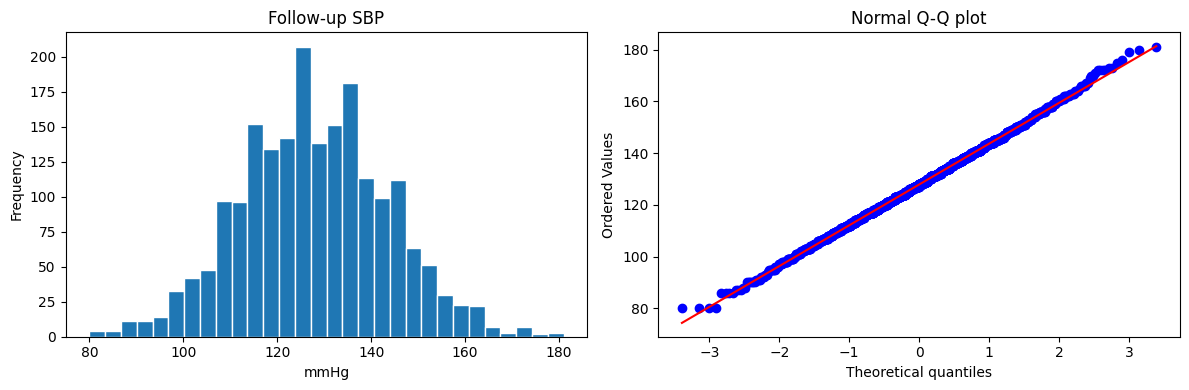

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["sbp_followup"].plot.hist(bins=30, ax=axes[0], edgecolor="white")
axes[0].set_title("Follow-up SBP")
axes[0].set_xlabel("mmHg")
stats.probplot(df["sbp_followup"], dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot")
plt.tight_layout()

Now look at how SBP relates to each predictor.

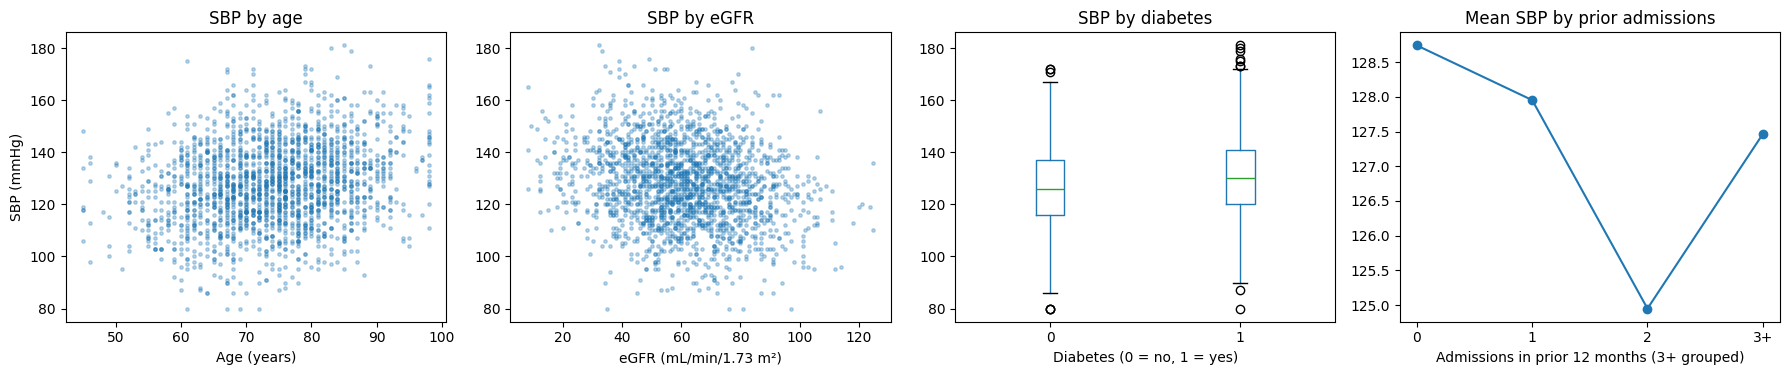

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].scatter(df["age"], df["sbp_followup"], s=6, alpha=0.3)
axes[0].set(title="SBP by age", xlabel="Age (years)", ylabel="SBP (mmHg)")
axes[1].scatter(df["egfr"], df["sbp_followup"], s=6, alpha=0.3)
axes[1].set(title="SBP by eGFR", xlabel="eGFR (mL/min/1.73 m²)")
df.boxplot(column="sbp_followup", by="diabetes", ax=axes[2], grid=False)
axes[2].set(title="SBP by diabetes", xlabel="Diabetes (0 = no, 1 = yes)")
by_prior = df.groupby(df["prior_admits_12m"].clip(upper=3))["sbp_followup"].agg(["mean", "size"])
axes[3].plot(["0", "1", "2", "3+"], by_prior["mean"], marker="o")
axes[3].set(title="Mean SBP by prior admissions", xlabel="Admissions in prior 12 months (3+ grouped)")
plt.suptitle("")
plt.tight_layout()

**Question 1.** Based on these plots, which distribution would you choose for follow-up SBP, and why?

*Answer.* SBP is continuous, roughly symmetric (the histogram is bell-shaped and the Q-Q plot is close to a straight line) and far from any boundary such as zero. Its spread looks similar across ages and eGFR values. A **Normal** distribution is the natural starting choice. Older patients and patients with diabetes have somewhat higher SBP; better kidney function goes with slightly lower SBP; and SBP tends to be lower in patients with more prior admissions (only 108 patients had 3 or more, so that point is noisy). These are unadjusted patterns. Patients with more admissions also more often have diabetes and low eGFR, both of which go with higher SBP, so the raw prior-admissions pattern understates its own effect; the model in Section 3 adjusts each predictor for the others.

## 2. Linear regression, the familiar way

Ordinary least squares (OLS) on the four predictors.

In [7]:
ols = smf.ols("sbp_followup" + RHS, data=df).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:           sbp_followup   R-squared:                       0.101
Model:                            OLS   Adj. R-squared:                  0.100
Method:                 Least Squares   F-statistic:                     56.23
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           5.34e-45
Time:                        12:24:52   Log-Likelihood:                -8244.7
No. Observations:                2000   AIC:                         1.650e+04
Df Residuals:                    1995   BIC:                         1.653e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          128.1167      0.498  

## 3. The same model as a GLM

Now fit it with `smf.glm`, choosing the **Gaussian** (Normal) family. Its default link is the **identity**: g(μ) = μ.

In [8]:
gauss = smf.glm("sbp_followup" + RHS, data=df, family=fam.Gaussian()).fit()
print(gauss.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           sbp_followup   No. Observations:                 2000
Model:                            GLM   Df Residuals:                     1995
Model Family:                Gaussian   Df Model:                            4
Link Function:               Identity   Scale:                          223.48
Method:                          IRLS   Log-Likelihood:                -8244.7
Date:                Thu, 29 Oct 2026   Deviance:                   4.4585e+05
Time:                        12:24:52   Pearson chi2:                 4.46e+05
No. Iterations:                     3   Pseudo R-squ. (CS):             0.1064
Covariance Type:            nonrobust                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          128.1167      0.498  

### The three components, inside the fitted model

In [9]:
print("1. Distribution (family):", type(gauss.family).__name__)
print("2. Linear predictor:     ", " + ".join(gauss.params.index))
print("3. Link function:        ", type(gauss.family.link).__name__)

1. Distribution (family): Gaussian
2. Linear predictor:      Intercept + age10 + egfr10 + diabetes + prior_admits_12m
3. Link function:         Identity


### Same model, same numbers

In [10]:
pd.DataFrame({
    "OLS estimate": ols.params, "GLM estimate": gauss.params,
    "OLS SE": ols.bse, "GLM SE": gauss.bse,
}).round(4)

,OLS estimate,GLM estimate,OLS SE,GLM SE
Intercept,128.1167,128.1167,0.4983,0.4983
age10,2.7783,2.7783,0.3559,0.3559
egfr10,-1.3641,-1.3641,0.1880,0.1880
diabetes,4.6286,4.6286,0.7020,0.7020
prior_admits_12m,-1.9620,-1.9620,0.3713,0.3713


With the identity link, the linear predictor η **is** the predicted mean. With other links (Parts 2 and 3) they differ.

In [11]:
eta = gauss.predict(which="linear")   # linear predictor
mu = gauss.predict()                  # predicted mean
print("Identical:", np.allclose(eta, mu))

Identical: True


## 5. Interpreting the coefficients

With the identity link, each coefficient is a **difference in mean SBP in mmHg**, holding the other predictors fixed.

In [12]:
ci = gauss.conf_int()
coef_table = pd.DataFrame({
    "estimate (mmHg)": gauss.params,
    "2.5%": ci[0],
    "97.5%": ci[1],
    "p-value": gauss.pvalues,
}).round(3)
coef_table

,estimate (mmHg),2.5%,97.5%,p-value
Intercept,128.117,127.140,129.093,0.0
age10,2.778,2.081,3.476,0.0
egfr10,-1.364,-1.732,-0.996,0.0
diabetes,4.629,3.253,6.005,0.0
prior_admits_12m,-1.962,-2.690,-1.234,0.0


Two worked interpretations:

- **Intercept.** The reference patient (75 years, eGFR 60, no diabetes, no prior admissions) has an expected follow-up SBP of about 128 mmHg.
- **Diabetes.** Patients with diabetes have a mean SBP about 4.6 mmHg higher (95% CI 3.3 to 6.0) than patients without diabetes of the same age, kidney function and admission history.

**Exercise 5a.** Write one sentence each for age, eGFR and prior admissions. Which coefficient might surprise a clinician, and what could explain it?

In [13]:
coef_table.loc[["age10", "egfr10", "prior_admits_12m"]]

,estimate (mmHg),2.5%,97.5%,p-value
age10,2.778,2.081,3.476,0.0
egfr10,-1.364,-1.732,-0.996,0.0
prior_admits_12m,-1.962,-2.690,-1.234,0.0


*Answer.*

- **Age:** each additional 10 years is associated with a mean SBP about 2.8 mmHg higher (2.1 to 3.5).
- **eGFR:** each 10 points of better kidney function is associated with a mean SBP about 1.4 mmHg lower (1.0 to 1.7 lower).
- **Prior admissions:** each admission in the past year is associated with a mean SBP about 2.0 mmHg lower (1.2 to 2.7 lower).

The negative prior-admissions effect may surprise people used to thinking of hypertension as a risk factor. In heart failure, repeated admissions are a marker of more advanced disease: lower cardiac output and more intensive diuretic and vasodilator therapy both push blood pressure down. Low SBP is itself a marker of poor prognosis in heart failure.

## 7. Checking the model

A Normal GLM with identity link assumes: a straight-line relationship with each predictor, constant spread, and roughly normal residuals. Residual plots check all three.

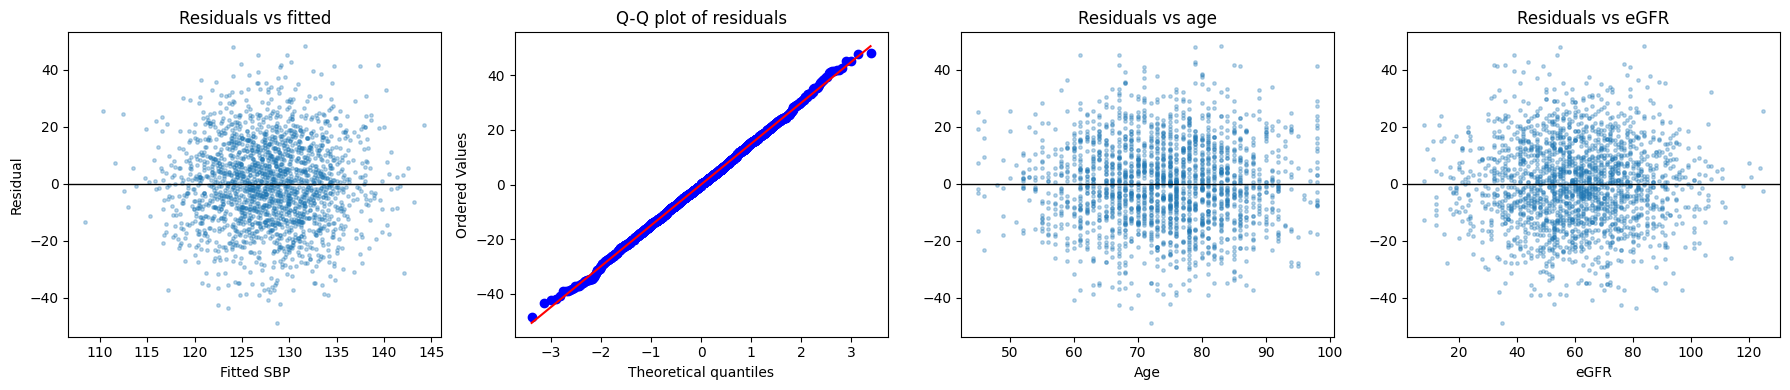

In [14]:
resid = gauss.resid_deviance   # for the Gaussian family these are the ordinary residuals
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].scatter(gauss.fittedvalues, resid, s=6, alpha=0.3)
axes[0].axhline(0, color="black", lw=1)
axes[0].set(title="Residuals vs fitted", xlabel="Fitted SBP", ylabel="Residual")
stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot of residuals")
axes[2].scatter(df["age"], resid, s=6, alpha=0.3)
axes[2].axhline(0, color="black", lw=1)
axes[2].set(title="Residuals vs age", xlabel="Age")
axes[3].scatter(df["egfr"], resid, s=6, alpha=0.3)
axes[3].axhline(0, color="black", lw=1)
axes[3].set(title="Residuals vs eGFR", xlabel="eGFR")
plt.tight_layout()

A formal check of constant variance: the Breusch–Pagan test (a small p-value means the spread changes with the predictors).

In [15]:
bp_p = sm.stats.het_breuschpagan(ols.resid, ols.model.exog)[1]
print(f"Breusch-Pagan p-value for SBP: {bp_p:.2f}")

Breusch-Pagan p-value for SBP: 0.86




### The effects built into the data

| Term | True effect | Estimate (95% CI) |
|---|---|---|
| Intercept (reference patient) | 128 mmHg | 128.1 (127.1 to 129.1) |
| Age, per 10 years | +3.0 | +2.8 (2.1 to 3.5) |
| eGFR, per +10 | −1.0 | −1.4 (−1.7 to −1.0) |
| Diabetes | +4.0 | +4.6 (3.3 to 6.0) |
| Each prior admission | −1.5 | −2.0 (−2.7 to −1.2) |
| Female | 0 | +0.6 (−0.7 to 1.9) |
| Residual SD | 15 | 14.9 |

The data were generated from a Normal model with constant variance and no interactions, which is why the identity-link Normal model fits best,